# 3 · Backstripping the Coastal Range, Taiwan

**What.** 1-D Airy backstripping of the northern (N) and southern (S) Coastal Range composite sections with Monte Carlo uncertainty.

**Why.** Separate how much the basin floor sank because of tectonics (plate flexure/collision) from how much is just the weight of sediment and water.

**Equations** (Lai et al. 2022; Watts 2001).

Decompaction — the solid (grain) thickness of a unit is conserved when it is moved up:

$$G = \int_{z_1}^{z_2}(1-\phi(z))\,dz = (z_2-z_1) - \phi_0 c\,(e^{-z_1/c}-e^{-z_2/c})$$

Bulk sediment density: $\rho_s = \dfrac{\sum_i [\phi_i\rho_w + (1-\phi_i)\rho_{g,i}]\,T_i}{\sum_i T_i}$

Airy tectonic subsidence:

$$\zeta = S\,\frac{\rho_a-\rho_s}{\rho_a-\rho_w} + W - \Delta SL\,\frac{\rho_a}{\rho_a-\rho_w}$$

| symbol | meaning |
|---|---|
| z₁, z₂ | top/base depth of a unit below seafloor (m) |
| φ₀, c | porosity–depth constants (notebook 1) |
| G | solid thickness (m) |
| T_i | decompacted thickness (m) |
| ρ_w, ρ_g, ρ_a | water, grain and asthenosphere density (kg m⁻³) |
| S | decompacted sediment thickness (total subsidence of basement) (m) |
| W | paleo-water depth (notebook 2) (m) |
| ΔSL | sea level relative to today (Miller et al. 2020) (m) |
| ζ | tectonic (water-loaded) subsidence (m) |

**Uncertainty.** Every input (age, thickness, water depth, sea level, φ₀, c, densities) is drawn from a normal distribution, n = 2000 times, and the backstrip is rerun. Bands are 16–84 % and 2.5–97.5 %. The original R code used the first-order delta method; that is kept in `pybasinsubs.legacy` (notebook 4).

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, ROOT)
IMG = os.path.join(ROOT, "image"); os.makedirs(IMG, exist_ok=True)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
def save(fig, name):
    fig.savefig(os.path.join(IMG, name), bbox_inches="tight"); print("saved image/" + name)

In [2]:
from pybasinsubs.column import from_basinsubs, MAX_ELEV_M
from pybasinsubs.backstrip import backstrip
from pybasinsubs.plotting import geohistory
res = {}
for reg in "NS":
    col = from_basinsubs(reg)
    res[reg] = backstrip(col, n=2000, seed=1)
col.units.head()

,unit,age_top_Ma,age_top_err_Ma,thickness_m,thickness_err_m,water_depth_m,water_depth_err_m,sea_level_m,sea_level_err_m,f_mudstone,f_sandstone_tw,f_marine_avg,eroded,eroded_at_Ma,water_depth_at_erosion_m,age_base_Ma
0,0,0.605598,0.023165,750.000000,250.000000,457.796985,457.796985,-56.005000,5.455434,0.500000,0.500000,0.0,1,NaN,0.0,0.820021
1,1,0.820021,0.018103,613.746033,143.840129,915.593971,274.832899,-38.761000,4.096201,0.317878,0.682122,0.0,0,NaN,0.0,1.018000
2,2,1.018000,0.002000,698.687236,145.320347,722.541814,139.432729,-30.791111,4.809581,0.176839,0.823161,0.0,0,NaN,0.0,1.180000
3,3,1.180000,0.001000,89.001999,36.757082,742.102106,120.886209,-18.945000,7.006365,0.247914,0.752086,0.0,0,NaN,0.0,1.215000
4,4,1.215000,0.011000,132.774379,39.113254,749.118539,114.038823,-22.303636,4.491615,0.375000,0.625000,0.0,0,NaN,0.0,1.231000


saved image/nb3_geohistory_N.png


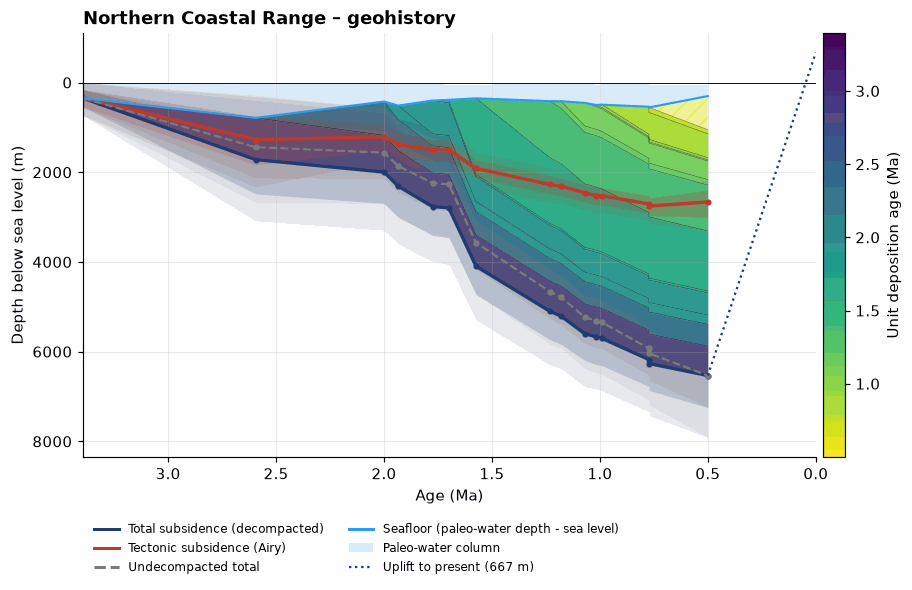

saved image/nb3_geohistory_S.png


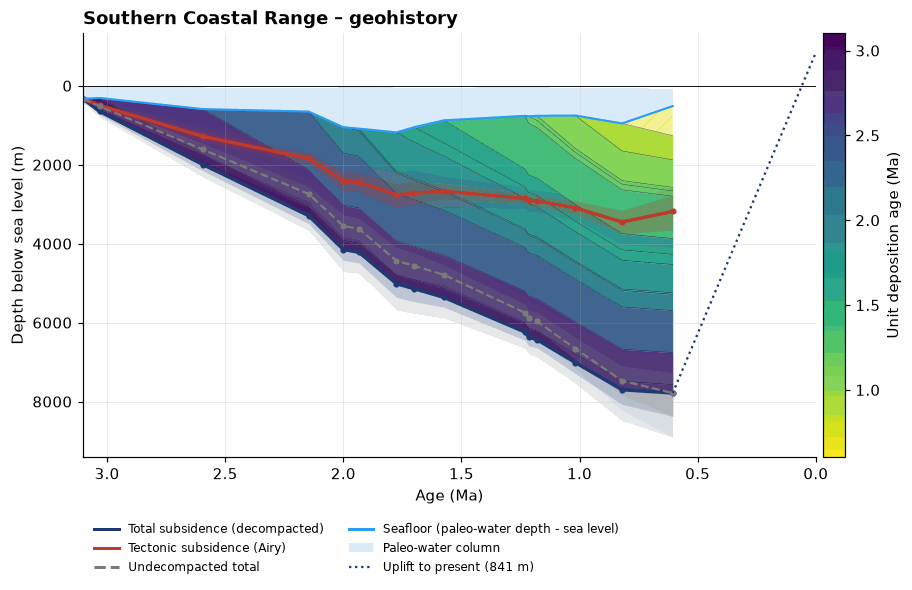

In [3]:
for reg, name in [("N", "Northern"), ("S", "Southern")]:
    fig, ax = plt.subplots(figsize=(9, 5))
    geohistory(res[reg], ax=ax, title=f"{name} Coastal Range – geohistory", present_elevation=MAX_ELEV_M[reg] / 2)
    save(fig, f"nb3_geohistory_{reg}.png"); plt.show()

**How to read the geohistory diagrams.** Time runs left (old) to right (now). Each coloured band is one stratigraphic unit, coloured by its age; it starts as a thin wedge at the seafloor when it is deposited and gets thinner (compacted) as it is buried.

- **Dark blue line**: depth of the base of the section (total subsidence, decompacted). Grey shading is its uncertainty.
- **Dashed grey**: the same thing without decompaction — always shallower, the gap is the compaction correction.
- **Red line**: tectonic subsidence — the part not caused by sediment and water loading. Red shading is its uncertainty.
- **Light blue**: the seafloor (paleo-water depth corrected for sea level).
- **Dotted line**: the jump from the youngest unit to its present elevation (half the maximum elevation, as in the paper), i.e. late uplift.

**Reading.** Both regions sank fast (several km in ~2 Myr), with the fastest tectonic subsidence before ~1.5 Ma, then were uplifted to above sea level in the last ~0.5 Myr — the record of a forearc basin being pulled down and then accreted in the arc–continent collision.

In [4]:
tab = res["N"].summary()
tab[["node", "age_Ma", "total_subsidence_m", "total_subsidence_m_p2.5", "total_subsidence_m_p97.5", "tectonic_subsidence_m", "tectonic_subsidence_m_p2.5", "tectonic_subsidence_m_p97.5"]].round(0)

,node,age_Ma,total_subsidence_m,total_subsidence_m_p2.5,total_subsidence_m_p97.5,tectonic_subsidence_m,tectonic_subsidence_m_p2.5,tectonic_subsidence_m_p97.5
0,14,3.0,349.0,-1.0,740.0,349.0,-2.0,738.0
1,13,3.0,1718.0,389.0,3088.0,1273.0,279.0,2337.0
2,12,2.0,1996.0,672.0,3297.0,1210.0,562.0,1726.0
3,11,2.0,2313.0,1025.0,3604.0,1381.0,799.0,1874.0
4,10,2.0,2766.0,1583.0,4000.0,1501.0,1017.0,1957.0
5,9,2.0,2794.0,1627.0,4062.0,1501.0,1018.0,1964.0
6,8,2.0,4095.0,3036.0,5296.0,1916.0,1544.0,2327.0
7,7,1.0,5102.0,4038.0,6301.0,2274.0,1887.0,2696.0
8,6,1.0,5208.0,4183.0,6386.0,2312.0,1940.0,2706.0
9,5,1.0,5601.0,4583.0,6785.0,2460.0,2112.0,2853.0


### Lithology sensitivity

The R code used the lithology of the **first row** of the litho table for every unit (a bug kept for parity in the legacy layer). The generic engine uses each unit's own lithology by default. The difference in total subsidence:

max |Δ total subsidence| = 43 m
saved image/nb3_lithology_sensitivity_N.png


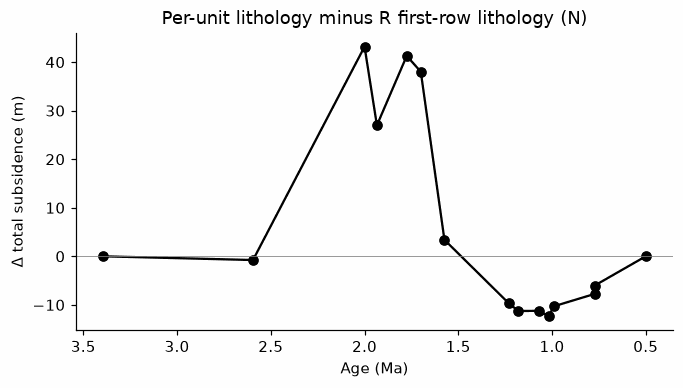

In [5]:
r_bug = backstrip(from_basinsubs("N", litho_mode="r_first_row"), n=0, mc=False)
r_ok = backstrip(from_basinsubs("N"), n=0, mc=False)
d = r_ok.summary().total_subsidence_m - r_bug.summary().total_subsidence_m
print(f"max |Δ total subsidence| = {abs(d).max():.0f} m")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(r_ok.summary().age_Ma, d, "o-", color="k"); ax.axhline(0, color="grey", lw=.5)
ax.invert_xaxis(); ax.set_xlabel("Age (Ma)"); ax.set_ylabel("Δ total subsidence (m)")
ax.set_title("Per-unit lithology minus R first-row lithology (N)")
save(fig, "nb3_lithology_sensitivity_N.png"); plt.show()

**Reading.** Positive values mean the per-unit lithology gives *more* decompacted subsidence. The difference is up to a few tens of metres — small compared with the water-depth uncertainty (hundreds of metres), so the paper's conclusions do not change.